# Capstone Checkpoint 1: EDA
Automated Job Application System. Datasets: LinkedIn Job Postings 2023-24 (arshkon) and US Job Postings 2023-05-05 (techmap).

In [1]:
# setup
import os, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# paths: unzip the LinkedIn zip into data/linkedin, put techmap_flat.csv (made by the flatten step below) in data/techmap
DATA = "data"
LI = os.path.join(DATA, "linkedin")
TM = os.path.join(DATA, "techmap")
FIG = "figs"
os.makedirs(FIG, exist_ok=True)

# simple consistent chart style
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a998f"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
def save(name):
    plt.savefig(os.path.join(FIG, name), facecolor="white")
    plt.show()

## 0. Techmap flatten step (run once)

In [2]:
# the techmap file is a 4.4 GB JSON-lines dump (one MongoDB doc per line) with a different nested layout per source site
# this streams it straight out of the zip and keeps the fields we need, so we never load 4.4 GB into memory
# set RUN_FLATTEN = True the first time; it writes techmap_flat.csv, techmap_flat_keys.json, techmap_flat_text_sample.jsonl
RUN_FLATTEN = False
if RUN_FLATTEN:
    import zipfile, hashlib, collections, csv
    zpath = os.path.join(DATA, "us_jobpostings_kaggle.zip")
    out = os.path.join(TM, "techmap_flat.csv")
    os.makedirs(TM, exist_ok=True)
    def g(d, *path):
        for p in path:
            if not isinstance(d, dict): return None
            d = d.get(p)
        return d
    def dt(x): return x.get("$date") if isinstance(x, dict) else x
    top_keys = collections.Counter()
    cols = ["id","source","idInSource","title","workType","employmentType","company","company_id","city","state","country",
            "url","dateCreated","datePosted","dateScraped","validThrough","text_len","html_len","text_hash","n_categories","category",
            "salary_text","careerLevel","industry","dateExpired","has_contact","n_datesUpdated"]
    with zipfile.ZipFile(zpath) as z, z.open(z.namelist()[0]) as fh, open(out, "w", newline="") as f, \
         open(out.replace(".csv", "_text_sample.jsonl"), "w") as samp:
        w = csv.writer(f); w.writerow(cols)
        for line in fh:
            d = json.loads(line); top_keys.update(d.keys())
            pos = d.get("position") or {}; so = g(d, "json", "schemaOrg") or {}
            oc = d.get("orgCompany") or {}; oa = d.get("orgAddress") or {}
            text = d.get("text") or ""; tags = g(d, "orgTags", "CATEGORIES") or []
            sal = d.get("salary") if isinstance(d.get("salary"), dict) else {}
            w.writerow([g(d,"_id","$oid"), d.get("source"), d.get("idInSource"), pos.get("name") or d.get("name"),
                        pos.get("workType"), so.get("employmentType"), oc.get("nameOrg") or oc.get("name"),
                        g(d,"companyID","$oid"), oa.get("city"), oa.get("state"), oa.get("countryCode"), d.get("url"),
                        dt(d.get("dateCreated")), so.get("datePosted"), dt(d.get("dateScraped")), so.get("validThrough"),
                        len(text), len(d.get("html") or ""), hashlib.md5(text.strip().lower().encode()).hexdigest(),
                        len(tags), tags[0] if tags else None, sal.get("text"), pos.get("careerLevel"),
                        json.dumps(so.get("industry"))[:150] if so.get("industry") else None,
                        dt(d.get("dateExpired")), int("contact" in d), len(d.get("datesUpdated") or [])])
            samp.write(json.dumps({"id": g(d,"_id","$oid"), "source": d.get("source"), "text": text}) + "\n")
    json.dump({"top_keys": top_keys}, open(out.replace(".csv", "_keys.json"), "w"), indent=1)

## 1. Load data

In [3]:
# LinkedIn: main postings table + lookup tables
li = pd.read_csv(os.path.join(LI, "postings.csv"))
job_skills = pd.read_csv(os.path.join(LI, "jobs/job_skills.csv"))
job_ind = pd.read_csv(os.path.join(LI, "jobs/job_industries.csv"))
benefits = pd.read_csv(os.path.join(LI, "jobs/benefits.csv"))
skills_map = pd.read_csv(os.path.join(LI, "mappings/skills.csv"))
ind_map = pd.read_csv(os.path.join(LI, "mappings/industries.csv"))
companies = pd.read_csv(os.path.join(LI, "companies/companies.csv"))
emp_counts = pd.read_csv(os.path.join(LI, "companies/employee_counts.csv"))

# techmap: flattened CSV + full description text
tm = pd.read_csv(os.path.join(TM, "techmap_flat.csv"))
tm_text = pd.read_json(os.path.join(TM, "techmap_flat_text_sample.jsonl"), lines=True)[["id", "text"]]
tm = tm.merge(tm_text, on="id", how="left")

for name, df in [("linkedin postings", li), ("job_skills", job_skills), ("job_industries", job_ind), ("benefits", benefits),
                 ("companies", companies), ("employee_counts", emp_counts), ("techmap", tm)]:
    print(f"{name:18s} rows={len(df):>8,}  cols={df.shape[1]}")

linkedin postings  rows= 123,849  cols=31
job_skills         rows= 213,768  cols=2
job_industries     rows= 164,808  cols=2
benefits           rows=  67,943  cols=3
companies          rows=  24,473  cols=10
employee_counts    rows=  35,787  cols=4
techmap            rows=  33,064  cols=40


In [4]:
# quick look at columns and types
li.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  str    
 2   title                       123849 non-null  str    
 3   description                 123842 non-null  str    
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   str    
 6   location                    123849 non-null  str    
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  str    
 12  applies                     23320 non-null   float64
 13  original_listed_time     

In [5]:
tm.drop(columns=["text"]).info()

<class 'pandas.DataFrame'>
RangeIndex: 33064 entries, 0 to 33063
Data columns (total 39 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      33064 non-null  str    
 1   source                  33064 non-null  str    
 2   idInSource              33064 non-null  str    
 3   title                   33064 non-null  str    
 4   workType                23890 non-null  str    
 5   employmentType          18522 non-null  str    
 6   company                 33064 non-null  str    
 7   company_id              33064 non-null  str    
 8   city                    30314 non-null  str    
 9   state                   29971 non-null  str    
 10  country                 16535 non-null  str    
 11  url                     33064 non-null  str    
 12  dateCreated             33064 non-null  str    
 13  datePosted              23451 non-null  str    
 14  dateScraped             33064 non-null  str    
 

## 2. Data quality report

In [6]:
# data quality summary table: rows, columns, duplicates, missing
def dq_table(df, key_cols, text_col):
    return pd.Series({
        "rows": len(df),
        "columns": df.shape[1],
        "duplicate ids": int(df.duplicated(key_cols).sum()),
        "duplicate descriptions": int(df[text_col].str.strip().str.lower().duplicated().sum()),
        "columns >50% missing": int((df.isna().mean() > 0.5).sum()),
        "overall % cells missing": round(df.isna().mean().mean() * 100, 1),
    })

dq = pd.DataFrame({
    "LinkedIn": dq_table(li, ["job_id"], "description"),
    "Techmap": dq_table(tm.drop(columns=["text_hash"]), ["source", "idInSource"], "text"),
})
dq

,LinkedIn,Techmap
rows,123849.0,33064.0
columns,31.0,39.0
duplicate ids,0.0,0.0
duplicate descriptions,16109.0,8713.0
columns >50% missing,11.0,12.0
overall % cells missing,33.1,34.2


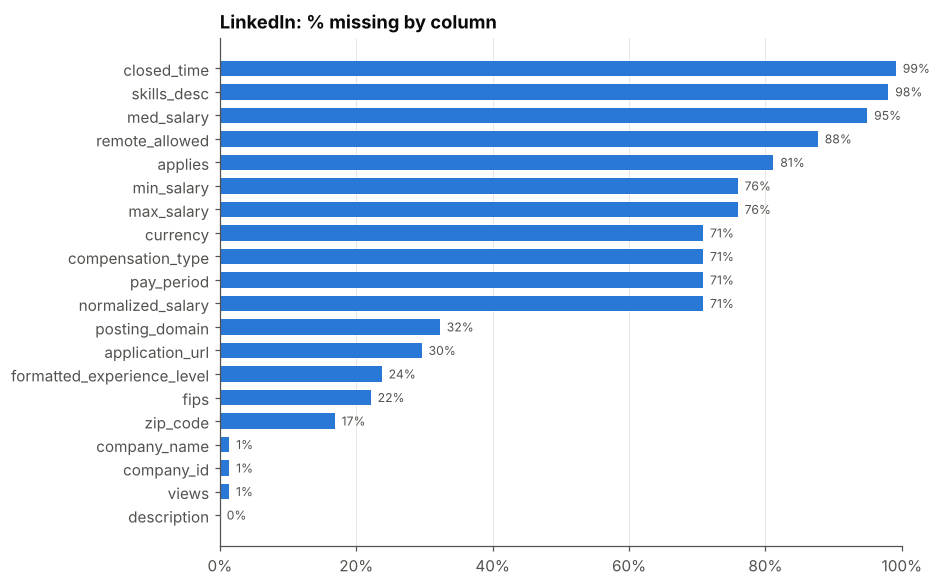

In [7]:
# missing % per column, LinkedIn
li_miss = li.isna().mean().sort_values(ascending=False) * 100
li_miss = li_miss[li_miss > 0]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(li_miss.index[::-1], li_miss.values[::-1], color=BLUE, height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100)
ax.set_title("LinkedIn: % missing by column")
ax.grid(axis="y", visible=False)
for i, v in enumerate(li_miss.values[::-1]):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8, color="#52514e")
save("li_missing.png")

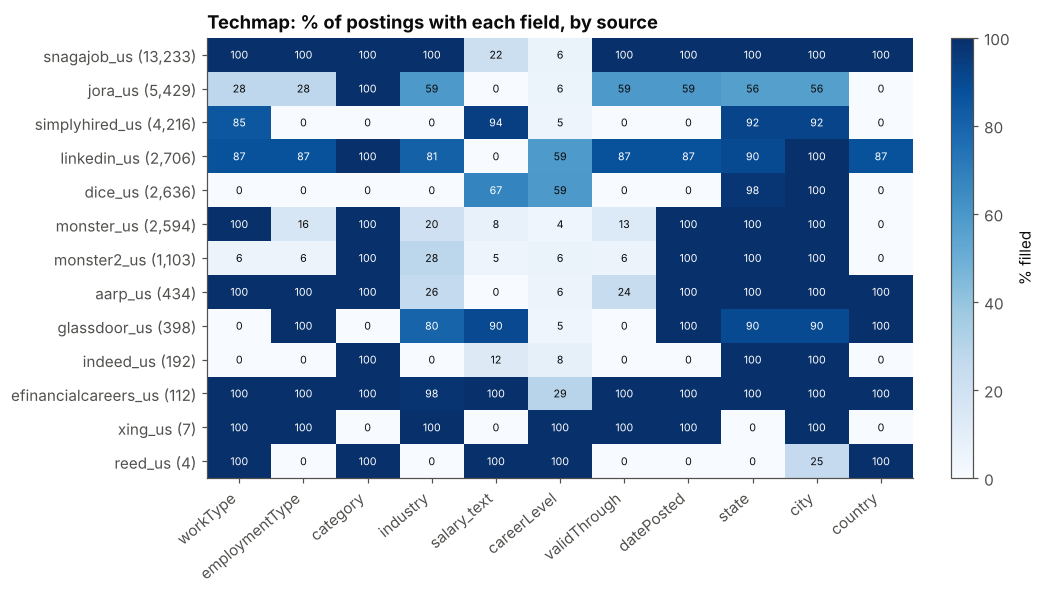

In [8]:
# techmap schema changes a lot by source site, so show field coverage per source (heatmap)
fields = ["workType", "employmentType", "category", "industry", "salary_text", "careerLevel",
          "validThrough", "datePosted", "state", "city", "country"]
cov = tm.groupby("source")[fields].apply(lambda d: d.notna().mean() * 100)
cov = cov.loc[tm.source.value_counts().index]  # order by volume
cov.index = [f"{s} ({n:,})" for s, n in tm.source.value_counts().items()]

fig, ax = plt.subplots(figsize=(9, 5.2))
im = ax.imshow(cov.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(fields)), fields, rotation=40, ha="right")
ax.set_yticks(range(len(cov)), cov.index)
ax.grid(False)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        v = cov.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "#0b0b0b")
ax.set_title("Techmap: % of postings with each field, by source")
plt.colorbar(im, ax=ax, fraction=0.03, label="% filled")
save("tm_field_coverage.png")

In [9]:
# salary columns: mixed pay periods + obvious entry errors
print(li.pay_period.value_counts(dropna=False))
print(li.groupby("pay_period").normalized_salary.describe()[["count", "50%", "max"]])

# examples of broken salaries (hourly jobs with yearly numbers, or $1 placeholders)
li[(li.normalized_salary > 1e6) | (li.normalized_salary < 10000)][
    ["title", "pay_period", "min_salary", "max_salary", "normalized_salary"]].head(10)

pay_period
NaN         87776
YEARLY      20628
HOURLY      14741
MONTHLY       518
WEEKLY        177
BIWEEKLY        9
Name: count, dtype: int64
              count        50%          max
pay_period                                 
BIWEEKLY        9.0  1572805.0    2096744.0
HOURLY      14741.0    52520.0  535600000.0
MONTHLY       518.0    53634.0    1200000.0
WEEKLY        177.0   109148.0     210548.0
YEARLY      20628.0   102000.0  102500000.0


,title,pay_period,min_salary,max_salary,normalized_salary
9,Worship Leader,MONTHLY,NaN,NaN,4200.0
266,Principal Backend Engineer,YEARLY,200.0,225.0,212.5
308,Records Specialist & Academic Scheduler,YEARLY,45.0,50.0,47.5
542,Commercial Real Estate Attorney,YEARLY,120.0,180.0,150.0
590,Construction Superintendent,YEARLY,120.0,150.0,135.0
1284,Data Entry Specialist,YEARLY,20.0,24.0,22.0
1450,Embedded Engineer,YEARLY,110.0,140.0,125.0
1473,Assistant Underwriter,YEARLY,28.0,30.0,29.0
1545,Seeking Hosts For Nonviolence Now Podcast,YEARLY,NaN,NaN,800.0
1616,Dental Receptionist,YEARLY,20.0,25.0,22.5


In [10]:
# applies is missing for ~81% of rows. check if that depends on how people apply
pd.crosstab(li.application_type, li.applies.isna(), normalize="index").round(3) * 100

applies,False,True
application_type,,
ComplexOnsiteApply,37.5,62.5
OffsiteApply,11.5,88.5
SimpleOnsiteApply,23.8,76.2
UnknownApply,100.0,0.0


In [11]:
# timestamps are epoch milliseconds -> convert, then check the collection window
for c in ["original_listed_time", "listed_time", "expiry", "closed_time"]:
    li[c + "_dt"] = pd.to_datetime(li[c], unit="ms")
li[[c for c in li.columns if c.endswith("_dt")]].agg(["min", "max"])

,original_listed_time_dt,listed_time_dt,expiry_dt,closed_time_dt
min,2023-12-05 21:08:53,2024-03-24 21:50:14,2024-04-12 06:30:48,2024-04-05 19:38:52
max,2024-04-20 00:26:43,2024-04-20 00:26:56,2024-10-17 00:26:36,2024-04-19 21:28:27


In [12]:
# techmap: the same field is written many ways depending on the source
print(tm.workType.value_counts().head(10))
print(tm.country.value_counts(dropna=False))
print(tm.salary_text.dropna().sample(8, random_state=1).to_string())

workType
[fulltime, parttime]     8865
fulltime                 5797
[fulltime]               3555
other                    2636
parttime                  818
[parttime]                803
parttime, fulltime        350
contractor                221
temporary, contractor     157
fulltime, permanent       125
Name: count, dtype: int64
country
NaN    16529
US     13349
us      3186
Name: count, dtype: int64
31652                             Dollar 24.50 an hour
379                        77251-106589 (USD per YEAR)
4776     Dollar 65,000.00 to  Dollar 200,000.00 hourly
28433                          USD150,000 - USD200,000
8580                             Dollar 65.00 per hour
26509             Dollar 35.00 to  Dollar 50.00 hourly
21414                  Dollar 80,000 -  Dollar 100,000
30490                             Dollar 19.25 an hour


## 3. Cleaning steps used for EDA (draft of the data prep plan)

In [13]:
# 1. salary: keep normalized (annual) salary only if USD and in a sane range
li["salary_clean"] = li.normalized_salary.where(
    (li.currency == "USD") & li.normalized_salary.between(15_000, 1_000_000))
print("rows with usable salary:", li.salary_clean.notna().sum(), f"({li.salary_clean.notna().mean():.1%})")

# 2. state from "City, ST" text; "United States" means nationwide/remote
li["state"] = li.location.str.extract(r",\s*([A-Z]{2})$")[0]
print("rows with a state:", f"{li.state.notna().mean():.1%}")

# 3. remote flag: NaN means not flagged remote
li["remote"] = li.remote_allowed.fillna(0).astype(int)

# 4. repost flag + days since first listed
li["days_since_original"] = (li.listed_time - li.original_listed_time) / 86_400_000
li["reposted"] = li.days_since_original > 1
li["listing_window_days"] = (li.expiry - li.listed_time) / 86_400_000

# 5. description length (words)
li["desc_words"] = li.description.str.split().str.len()
tm["desc_words"] = tm.text.str.split().str.len()

# 6. duplicate description flag (same text posted more than once)
li["dup_desc"] = li.description.str.strip().str.lower().duplicated(keep=False)
tm["dup_desc"] = tm.text_hash.duplicated(keep=False)

# 7. techmap: normalise workType into one label
def norm_wt(x):
    if pd.isna(x): return np.nan
    x = str(x).lower()
    if "full" in x and "part" in x: return "Full or part-time"
    if "full" in x or "permanent" in x: return "Full-time"
    if "part" in x: return "Part-time"
    if "contract" in x or "temp" in x: return "Contract/Temp"
    return "Other"
tm["work_type_clean"] = tm.workType.map(norm_wt)

# 8. techmap: parse salary text into an annual number (midpoint of range)
def parse_salary(s):
    if pd.isna(s): return np.nan
    s = str(s).lower().replace(",", "")
    nums = [float(n) * (1000 if k else 1) for n, k in re.findall(r"(\d+(?:\.\d+)?)\s*(k)?", s)]
    nums = [n for n in nums if n > 0]
    if not nums: return np.nan
    v = np.mean(nums[:2])
    if "hour" in s or (v < 200 and "year" not in s): v *= 2080
    elif "week" in s and "biweek" not in s: v *= 52
    elif "biweek" in s: v *= 26
    elif "month" in s: v *= 12
    return v if 15_000 <= v <= 1_000_000 else np.nan
tm["salary_clean"] = tm.salary_text.map(parse_salary)
print("techmap rows with usable salary:", tm.salary_clean.notna().sum(), f"({tm.salary_clean.notna().mean():.1%})")

rows with usable salary: 35567 (28.7%)
rows with a state: 84.9%


techmap rows with usable salary: 7740 (23.4%)


## 4. Distributions

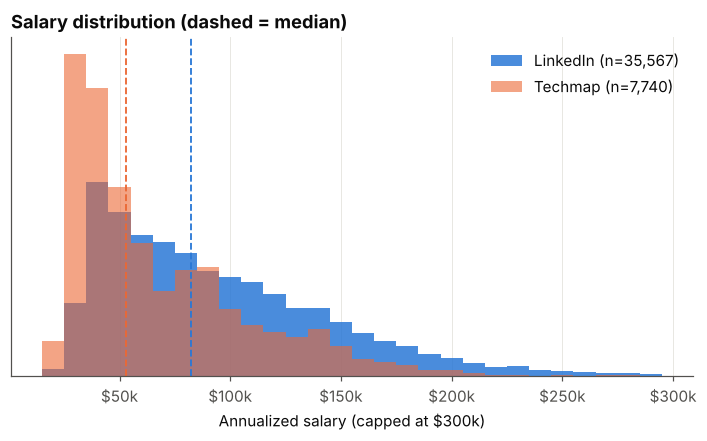

median LinkedIn: 82500.0  median techmap: 52800.0


In [14]:
# annual salary histogram, LinkedIn vs techmap
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(15_000, 300_001, 10_000)
ax.hist(li.salary_clean.dropna().clip(upper=300_000), bins=bins, color=BLUE, alpha=0.85, label=f"LinkedIn (n={li.salary_clean.notna().sum():,})", density=True)
ax.hist(tm.salary_clean.dropna().clip(upper=300_000), bins=bins, color=ORANGE, alpha=0.6, label=f"Techmap (n={tm.salary_clean.notna().sum():,})", density=True)
ax.axvline(li.salary_clean.median(), color=BLUE, ls="--", lw=1.2)
ax.axvline(tm.salary_clean.median(), color=ORANGE, ls="--", lw=1.2)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
ax.set_yticks([])
ax.set_xlabel("Annualized salary (capped at $300k)")
ax.set_title("Salary distribution (dashed = median)")
ax.legend(frameon=False)
save("salary_hist.png")
print("median LinkedIn:", li.salary_clean.median(), " median techmap:", tm.salary_clean.median())

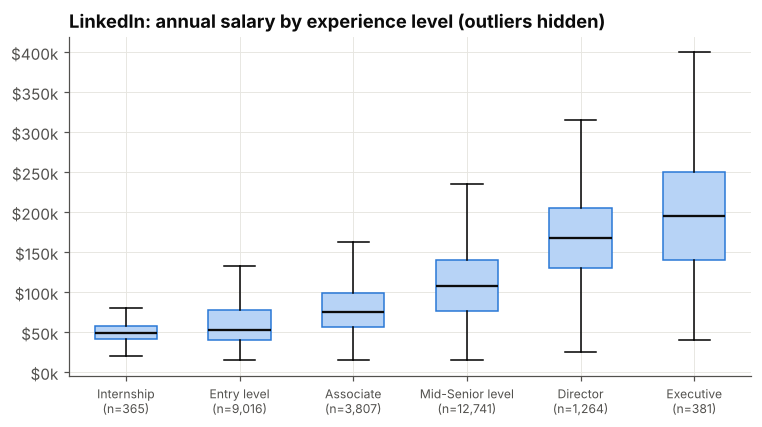

formatted_experience_level
Internship           48880.0
Entry level          52500.0
Associate            74994.4
Mid-Senior level    108160.0
Director            167500.0
Executive           195000.0
Name: salary_clean, dtype: float64

In [15]:
# salary by experience level (box plot)
order = ["Internship", "Entry level", "Associate", "Mid-Senior level", "Director", "Executive"]
data = [li.loc[li.formatted_experience_level == o, "salary_clean"].dropna() for o in order]
fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot(data, tick_labels=[f"{o}\n(n={len(d):,})" for o, d in zip(order, data)], showfliers=False,
                patch_artist=True, widths=0.55, medianprops=dict(color="#0b0b0b", lw=1.5))
for b in bp["boxes"]:
    b.set(facecolor="#b7d3f6", edgecolor=BLUE)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
ax.set_title("LinkedIn: annual salary by experience level (outliers hidden)")
ax.tick_params(axis="x", labelsize=8)
save("salary_by_level.png")
li.groupby("formatted_experience_level").salary_clean.median().reindex(order)

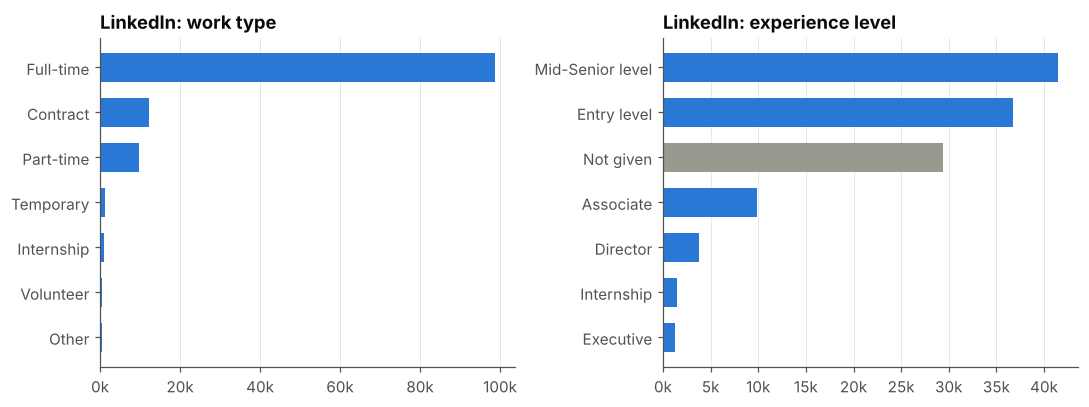

remote share: 12.3%


In [16]:
# work type and experience level counts
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
wt = li.formatted_work_type.value_counts()
axes[0].barh(wt.index[::-1], wt.values[::-1], color=BLUE, height=0.65)
axes[0].set_title("LinkedIn: work type")
lvl = li.formatted_experience_level.fillna("Not given").value_counts()
axes[1].barh(lvl.index[::-1], lvl.values[::-1], color=[GRAY if i == "Not given" else BLUE for i in lvl.index[::-1]], height=0.65)
axes[1].set_title("LinkedIn: experience level")
for a in axes:
    a.grid(axis="y", visible=False)
    a.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
plt.tight_layout()
save("li_worktype_level.png")
print("remote share:", f"{li.remote.mean():.1%}")

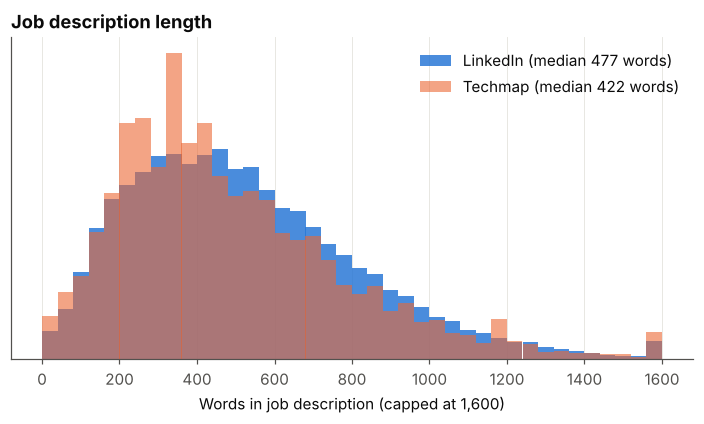

1263 LinkedIn postings under 50 words; 529 techmap


In [17]:
# description length, both datasets (matters for text models / resume matching)
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0, 1601, 40)
ax.hist(li.desc_words.clip(upper=1600), bins=bins, color=BLUE, alpha=0.85, density=True, label=f"LinkedIn (median {li.desc_words.median():.0f} words)")
ax.hist(tm.desc_words.clip(upper=1600), bins=bins, color=ORANGE, alpha=0.6, density=True, label=f"Techmap (median {tm.desc_words.median():.0f} words)")
ax.set_yticks([])
ax.set_xlabel("Words in job description (capped at 1,600)")
ax.set_title("Job description length")
ax.legend(frameon=False)
save("desc_length.png")
print((li.desc_words < 50).sum(), "LinkedIn postings under 50 words;", (tm.desc_words < 50).sum(), "techmap")

## 5. Engagement: views vs applies (LinkedIn)

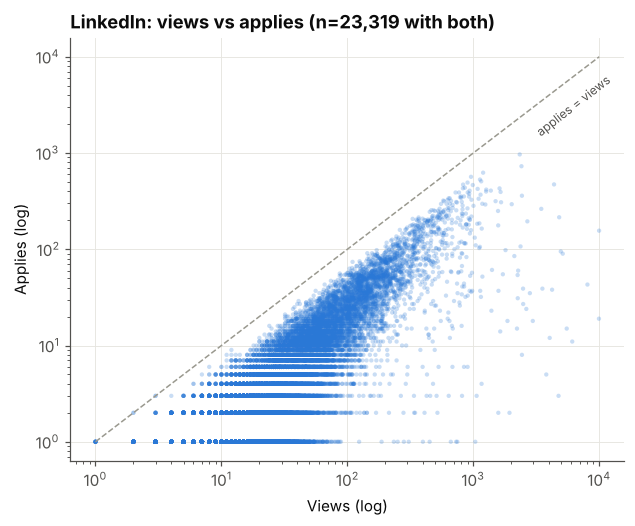

corr (log views, log applies): 0.84
median apply rate: 0.149
count    122160.000000
mean         14.618247
std          85.903598
min           1.000000
25%           3.000000
50%           4.000000
75%           8.000000
max        9975.000000
Name: views, dtype: float64


In [18]:
# views and applies are heavily right skewed, so use log scales
eng = li.dropna(subset=["views", "applies"])
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(eng.views, eng.applies, s=8, alpha=0.25, color=BLUE, edgecolors="none")
ax.set_xscale("log"); ax.set_yscale("log")
lims = [1, 1e4]
ax.plot(lims, lims, color=GRAY, lw=1, ls="--")
ax.text(3000, 1500, "applies = views", color="#52514e", fontsize=8, rotation=38)
ax.set_xlabel("Views (log)"); ax.set_ylabel("Applies (log)")
ax.set_title(f"LinkedIn: views vs applies (n={len(eng):,} with both)")
save("views_vs_applies.png")

eng = eng.assign(apply_rate=eng.applies / eng.views)
print("corr (log views, log applies):", round(np.corrcoef(np.log(eng.views), np.log(eng.applies))[0, 1], 2))
print("median apply rate:", round(eng.apply_rate.median(), 3))
print(li.views.describe())

In [19]:
# apply rate by experience level
eng.groupby("formatted_experience_level").apply_rate.median().sort_values()

formatted_experience_level
Executive           0.111111
Director            0.122807
Entry level         0.142857
Mid-Senior level    0.154564
Associate           0.166667
Internship          0.166667
Name: apply_rate, dtype: float64

## 6. Skills, industries, companies, locations

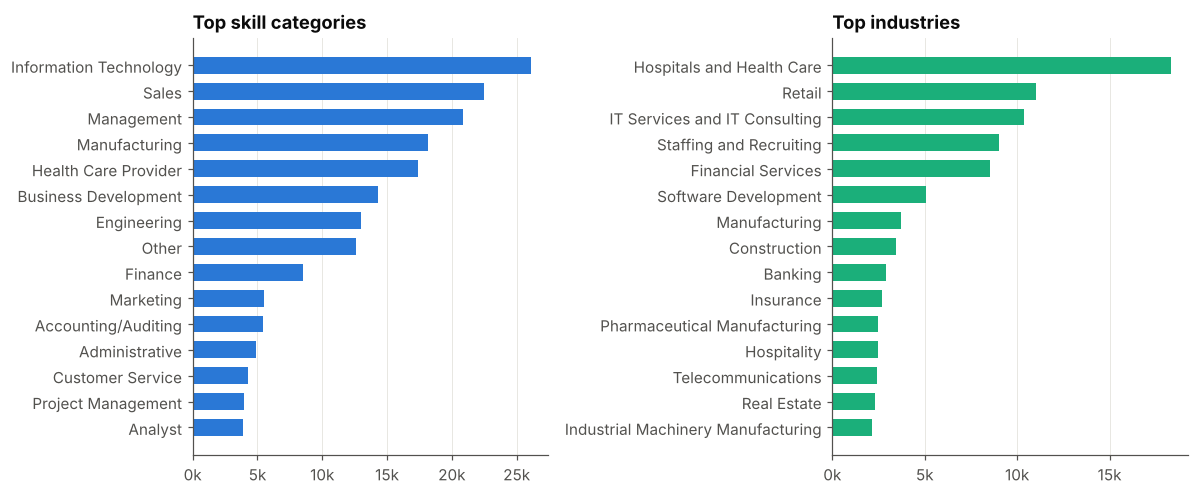

postings with at least one skill tag: 98.6%
skill tags per posting: {'mean': 1.685774444628451, '50%': 2.0, 'max': 3.0}
distinct skill categories: 35


In [20]:
# top LinkedIn skill categories (job_skills.csv joined to the mapping table)
sk = job_skills.merge(skills_map, on="skill_abr").skill_name.value_counts().head(15)
ind = job_ind.merge(ind_map, on="industry_id").industry_name.value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].barh(sk.index[::-1], sk.values[::-1], color=BLUE, height=0.65); axes[0].set_title("Top skill categories")
axes[1].barh(ind.index[::-1], ind.values[::-1], color=AQUA, height=0.65); axes[1].set_title("Top industries")
for a in axes:
    a.grid(axis="y", visible=False)
    a.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
plt.tight_layout()
save("li_skills_industries.png")
print("postings with at least one skill tag:", f"{li.job_id.isin(job_skills.job_id).mean():.1%}")
print("skill tags per posting:", job_skills.groupby("job_id").size().describe()[["mean", "50%", "max"]].to_dict())
print("distinct skill categories:", skills_map.shape[0])

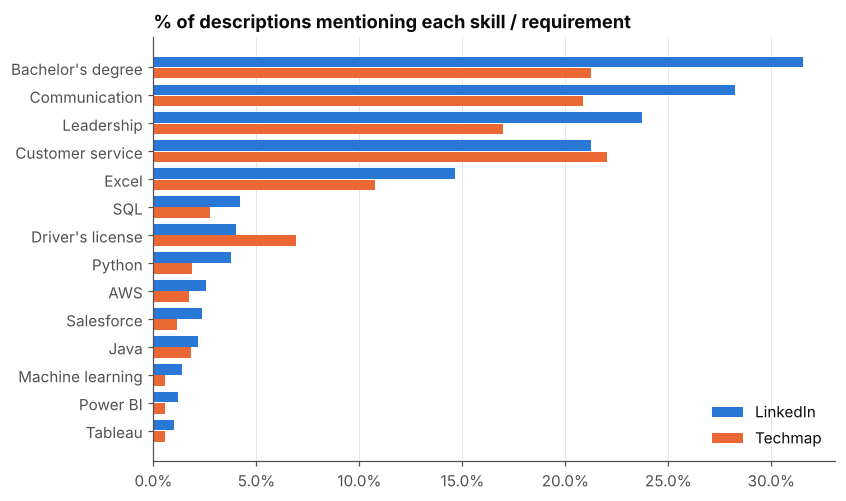

,LinkedIn,Techmap
Tableau,1.0,0.6
Power BI,1.2,0.6
Machine learning,1.4,0.5
Java,2.2,1.8
Salesforce,2.3,1.1
AWS,2.6,1.7
Python,3.8,1.9
Driver's license,4.0,6.9
SQL,4.2,2.7
Excel,14.6,10.7


In [21]:
# keyword scan of descriptions for concrete skills (preview of what O*NET matching will need to catch)
kw = {"Excel": r"\bexcel\b", "SQL": r"\bsql\b", "Python": r"\bpython\b", "Salesforce": r"\bsalesforce\b",
      "Java": r"\bjava\b", "AWS": r"\baws\b", "Tableau": r"\btableau\b", "Power BI": r"\bpower ?bi\b",
      "Communication": r"communication skills", "Leadership": r"\bleadership\b", "Customer service": r"customer service",
      "Bachelor's degree": r"bachelor", "Driver's license": r"driver'?s licen", "Machine learning": r"machine learning"}
li_low = li.description.str.lower(); tm_low = tm.text.fillna("").str.lower()
kw_df = pd.DataFrame({
    "LinkedIn": {k: li_low.str.contains(p, regex=True).mean() * 100 for k, p in kw.items()},
    "Techmap": {k: tm_low.str.contains(p, regex=True).mean() * 100 for k, p in kw.items()},
}).sort_values("LinkedIn")

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(kw_df))
ax.barh(y + 0.2, kw_df.LinkedIn, height=0.38, color=BLUE, label="LinkedIn")
ax.barh(y - 0.2, kw_df.Techmap, height=0.38, color=ORANGE, label="Techmap")
ax.set_yticks(y, kw_df.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("% of descriptions mentioning each skill / requirement")
ax.legend(frameon=False, loc="lower right")
save("keyword_mentions.png")
kw_df.round(1)

In [22]:
# where are the jobs: top states in each dataset (share of postings that have a state)
li_st = li.state.value_counts(normalize=True).head(12) * 100
tm_st = tm.state.value_counts(normalize=True).head(12) * 100
pd.DataFrame({"LinkedIn %": li_st.round(1), "Techmap %": tm_st.round(1)}).sort_values("LinkedIn %", ascending=False)

,LinkedIn %,Techmap %
state,,
CA,10.9,8.3
TX,9.8,7.8
NY,5.8,3.6
FL,5.6,4.1
NC,4.7,2.9
IL,4.3,NaN
PA,3.9,3.2
VA,3.5,3.1
GA,3.3,3.3


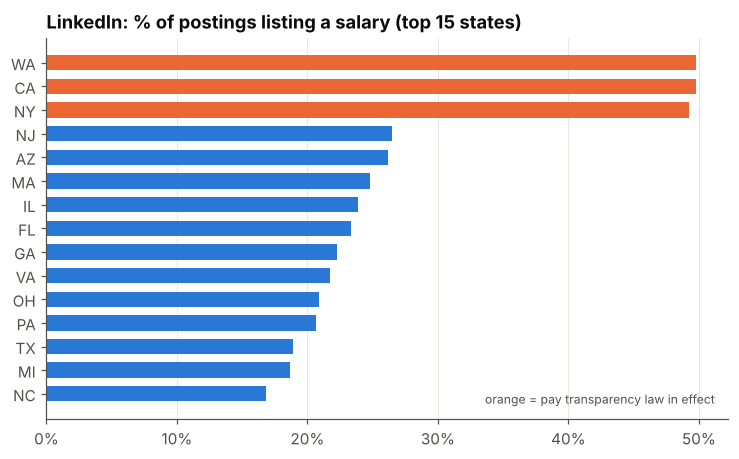

law states: 49.6 % | other states: 22.1 %


In [23]:
# salary disclosure by state: pay transparency law states (CA, CO, NY, WA) vs the rest
li["has_salary"] = li.salary_clean.notna()
top_states = li.state.value_counts().head(15).index
disc = li[li.state.isin(top_states)].groupby("state").has_salary.mean().sort_values() * 100
law = {"CA", "CO", "NY", "WA"}
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(disc.index, disc.values, color=[ORANGE if s in law else BLUE for s in disc.index], height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("LinkedIn: % of postings listing a salary (top 15 states)")
ax.text(0.98, 0.04, "orange = pay transparency law in effect", transform=ax.transAxes, ha="right", fontsize=8, color="#52514e")
save("salary_disclosure_state.png")
print("law states:", round(li[li.state.isin(law)].has_salary.mean() * 100, 1), "% | other states:",
      round(li[li.state.notna() & ~li.state.isin(law)].has_salary.mean() * 100, 1), "%")

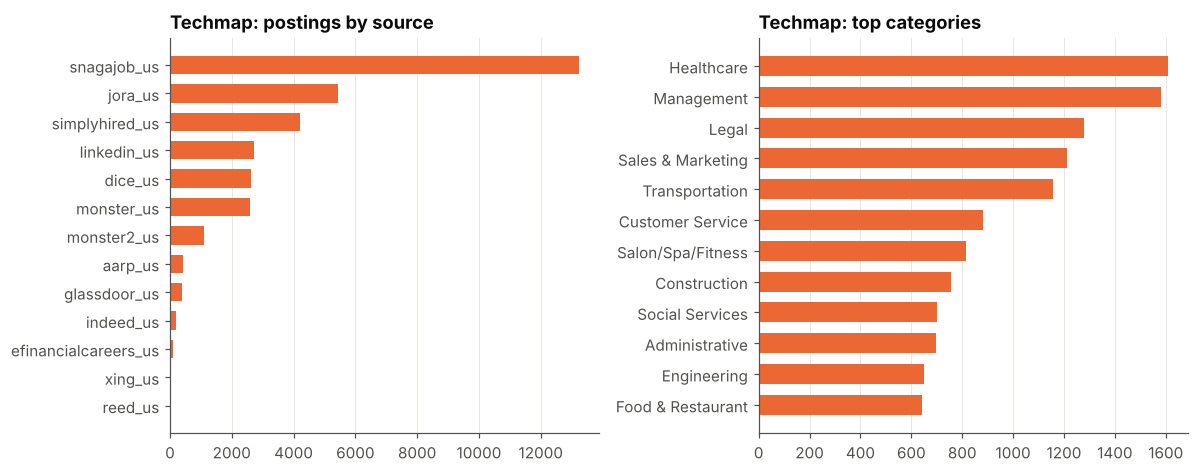

In [24]:
# techmap sources and categories
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
src = tm.source.value_counts()
axes[0].barh(src.index[::-1], src.values[::-1], color=ORANGE, height=0.65); axes[0].set_title("Techmap: postings by source")
cat = tm.category.value_counts().head(12)
axes[1].barh(cat.index[::-1], cat.values[::-1], color=ORANGE, height=0.65); axes[1].set_title("Techmap: top categories")
for a in axes: a.grid(axis="y", visible=False)
plt.tight_layout()
save("tm_sources_categories.png")

## 7. Ghost / low-quality posting signals

In [25]:
# no ghost label in either dataset, so look at proxy signals we can engineer later
# duplicate descriptions: same text posted many times
dup = pd.DataFrame({
    "dataset": ["LinkedIn", "Techmap"],
    "% rows sharing a description": [li.dup_desc.mean() * 100, tm.dup_desc.mean() * 100],
})
print(dup.round(1))

# who posts the same text the most
li_dup_co = li[li.dup_desc].company_name.value_counts().head(8)
tm_dup_src = tm.groupby("source").dup_desc.mean().sort_values(ascending=False) * 100
print(li_dup_co); print(tm_dup_src.round(1))

# same description across different job boards in techmap (cross-posting)
cross = tm.groupby("text_hash").source.nunique()
print("techmap descriptions that appear on 2+ boards:", (cross > 1).sum())

    dataset  % rows sharing a description
0  LinkedIn                          18.0
1   Techmap                          31.6
company_name
J. Galt                        597
Ingersoll Rand                 466
Cogent Communications          459
Capital One                    439
Lowe's Companies, Inc.         438
SKF Group                      309
Millennium Recruiting, Inc.    284
Macy's                         282
Name: count, dtype: int64
source
snagajob_us             68.3
reed_us                 50.0
efinancialcareers_us    30.4
monster2_us             22.9
linkedin_us              9.9
glassdoor_us             9.8
monster_us               8.5
simplyhired_us           7.9
aarp_us                  4.8
jora_us                  4.3
indeed_us                1.0
dice_us                  0.0
xing_us                  0.0
Name: dup_desc, dtype: float64
techmap descriptions that appear on 2+ boards: 63


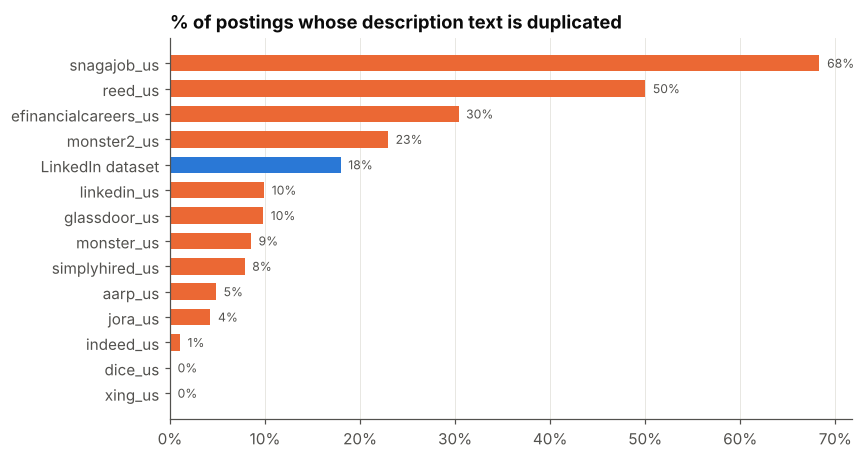

In [26]:
# bar: duplicate share by techmap source + LinkedIn
d = tm_dup_src.copy()
d.loc["LinkedIn dataset"] = li.dup_desc.mean() * 100
d = d.sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(d.index, d.values, color=[BLUE if i == "LinkedIn dataset" else ORANGE for i in d.index], height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("% of postings whose description text is duplicated")
for i, v in enumerate(d.values):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=8, color="#52514e")
save("duplicate_share.png")

reposted share: 8.6%
count    10664.000000
mean         5.917894
std          9.382781
min          1.004502
25%          1.133171
50%          1.199699
75%          3.010243
max        135.758507
Name: days_since_original, dtype: float64
listing_window_days
30.0     119142
180.0      3972
14.0        298
60.0        161
27.0         41
Name: count, dtype: int64


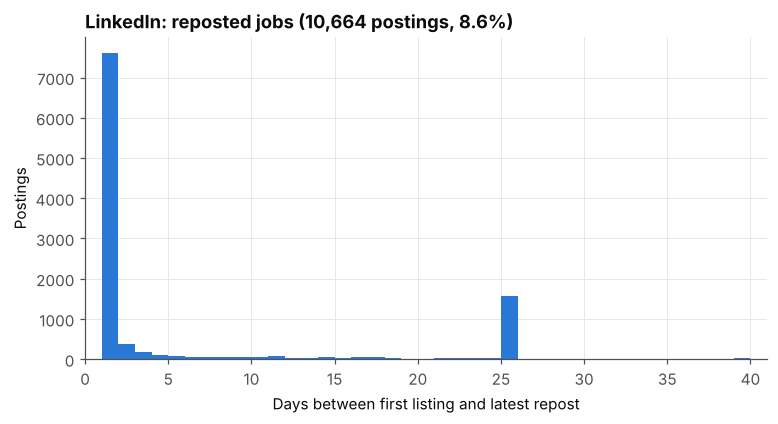

reposted within 2 days: 7617 | 25-30 days later: 1588


In [27]:
# reposting and listing windows (LinkedIn)
print("reposted share:", f"{li.reposted.mean():.1%}")
print(li.loc[li.reposted, "days_since_original"].describe())
print(li.listing_window_days.round().value_counts().head(5))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(li.loc[li.reposted, "days_since_original"].clip(upper=40), bins=np.arange(1, 41, 1), color=BLUE)
ax.set_xlim(0, 41)
ax.set_xlabel("Days between first listing and latest repost")
ax.set_ylabel("Postings")
ax.set_title(f"LinkedIn: reposted jobs ({li.reposted.sum():,} postings, {li.reposted.mean():.1%})")
save("repost_days.png")
print("reposted within 2 days:", (li.days_since_original.between(1, 2)).sum(), "| 25-30 days later:", (li.days_since_original.between(25, 30)).sum())

In [28]:
# do reposted jobs look different? (salary listed, views, apply rate)
cmp = li.assign(apply_rate=li.applies / li.views).groupby("reposted").agg(
    postings=("job_id", "size"), salary_listed=("has_salary", "mean"), median_views=("views", "median"),
    median_apply_rate=("apply_rate", "median"), dup_desc=("dup_desc", "mean"), median_words=("desc_words", "median"))
cmp

,postings,salary_listed,median_views,median_apply_rate,dup_desc,median_words
reposted,,,,,,
False,113185,0.289720,4.0,0.150,0.175438,466.0
True,10664,0.260221,4.0,0.125,0.223368,585.0


In [29]:
# combine proxy flags into a rough "ghost risk" count, just to see how flags overlap
li["flag_repost"] = li.reposted
li["flag_dup"] = li.dup_desc
li["flag_no_salary"] = ~li.has_salary
li["flag_short_desc"] = li.desc_words < 100
li["flag_low_rate"] = (li.views >= 50) & (li.applies.fillna(0) / li.views < 0.02)
flags = ["flag_repost", "flag_dup", "flag_no_salary", "flag_short_desc", "flag_low_rate"]
li["ghost_flags"] = li[flags].sum(axis=1)
print(li[flags].mean().round(3) * 100)
li.ghost_flags.value_counts().sort_index()

flag_repost         8.6
flag_dup           18.0
flag_no_salary     71.3
flag_short_desc     3.1
flag_low_rate       0.3
dtype: float64


ghost_flags
0    28551
1    67536
2    25416
3     2339
4        7
Name: count, dtype: int64

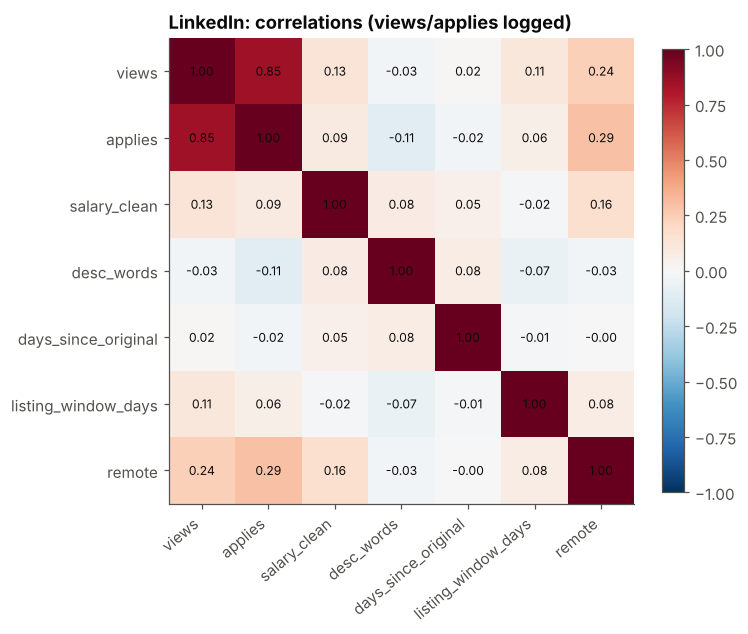

In [30]:
# correlation between numeric fields (LinkedIn)
num = li[["views", "applies", "salary_clean", "desc_words", "days_since_original", "listing_window_days", "remote"]].copy()
num["views"] = np.log1p(num.views); num["applies"] = np.log1p(num.applies)
corr = num.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("LinkedIn: correlations (views/applies logged)")
plt.colorbar(im, ax=ax, fraction=0.04)
save("li_corr.png")

## 8. Summary numbers for slides

In [31]:
summary = {
    "li_rows": len(li), "tm_rows": len(tm),
    "li_salary_pct": li.salary_clean.notna().mean() * 100, "tm_salary_pct": tm.salary_clean.notna().mean() * 100,
    "li_applies_missing_pct": li.applies.isna().mean() * 100,
    "li_dup_pct": li.dup_desc.mean() * 100, "tm_dup_pct": tm.dup_desc.mean() * 100,
    "li_repost_pct": li.reposted.mean() * 100, "li_remote_pct": li.remote.mean() * 100,
    "li_median_salary": li.salary_clean.median(), "tm_median_salary": tm.salary_clean.median(),
    "li_median_words": li.desc_words.median(), "tm_median_words": tm.desc_words.median(),
    "li_median_views": li.views.median(), "median_apply_rate": eng.apply_rate.median(),
    "law_salary_pct": li[li.state.isin(law)].has_salary.mean() * 100,
    "other_salary_pct": li[li.state.notna() & ~li.state.isin(law)].has_salary.mean() * 100,
    "li_exp_missing_pct": li.formatted_experience_level.isna().mean() * 100,
    "li_skill_tag_pct": li.job_id.isin(job_skills.job_id).mean() * 100,
}
json.dump({k: float(v) for k, v in summary.items()}, open("summary.json", "w"), indent=1)
pd.Series(summary).round(1)

li_rows                   123849.0
tm_rows                    33064.0
li_salary_pct                 28.7
tm_salary_pct                 23.4
li_applies_missing_pct        81.2
li_dup_pct                    18.0
tm_dup_pct                    31.6
li_repost_pct                  8.6
li_remote_pct                 12.3
li_median_salary           82500.0
tm_median_salary           52800.0
li_median_words              477.0
tm_median_words              422.0
li_median_views                4.0
median_apply_rate              0.1
law_salary_pct                49.6
other_salary_pct              22.1
li_exp_missing_pct            23.7
li_skill_tag_pct              98.6
dtype: float64